# Interpretability 10A: swap

The task has 9 inputs bits $x_1, \cdots, x_9\in\{0,1\}$ and one output bit $y\in \{0,1\}$.

$y = {\rm maj}({\rm maj}(x_1,x_2,x_3), {\rm maj}(x_4,x_5,x_6), {\rm maj}(x_7,x_8,x_9))$

where ${\rm maj}$ outputs 1 and two or three input bits are 1, otherwise outputs 0.

**KAN**

In [1]:
import torch
import numpy as np
from xkan import KANNetwork, create_dataset_from_data, fit
from xkan.interp import auto_swap, prune
from xkan.viz import plot

seed = 5
torch.manual_seed(seed)
np.random.seed(seed)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)


inputs = []
for i in range(2**9):
    string = "{0:b}".format(i)
    sample = [int(string[i]) for i in range(len(string))]
    sample = (9 - len(sample)) * [0] + sample
    inputs.append(sample)
   
inputs = np.array(inputs).astype(np.float32)
middle = np.array([np.sum(inputs[:,:3], axis=1) > 1.5, np.sum(inputs[:,3:6], axis=1) > 1.5, np.sum(inputs[:,6:9], axis=1) > 1.5]).astype(np.float32)
labels = (np.sum(middle, axis=0) > 1.5).astype(np.float32)[:,None]
inputs = torch.tensor(inputs)
labels = torch.tensor(labels)


train, test = create_dataset_from_data(inputs, labels, device=device)

width = [9, 10, 10, 1]
model = KANNetwork(width, seed=seed, noise_scale=1.0, device=device)
depth = len(width) - 1

def train_acc():
    return torch.mean(((model(train['x']) > 0.5) == train['y']).float())

def test_acc():
    return torch.mean(((model(test['x']) > 0.5) == test['y']).float())


history = fit(model, train, test, lamb=0.001, lamb_entropy=5., steps=20, stop_grid_update_step=1000)
print('train RMSE', history['train/y'][-1] ** 0.5, 'train_acc', train_acc().item(), 'test_acc', test_acc().item())

cuda


train RMSE 0.004254329474441113 train_acc 1.0 test_acc 1.0


In [2]:
#plot(model, train['x'])

In [3]:
model = auto_swap(model, train['x'])

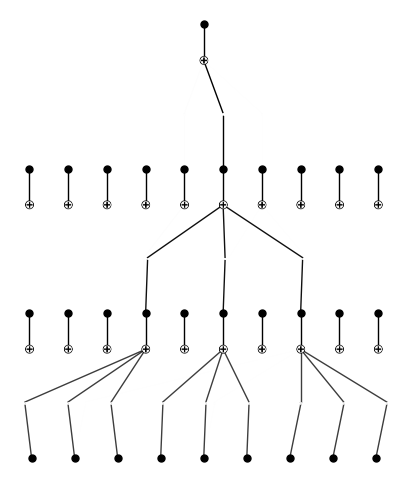

In [4]:
plot(model, train['x']);

In [5]:
model = prune(model, train['x'], node_th=5e-2)
model.width

[[9, 0], [3, 0], [1, 0], [1, 0]]

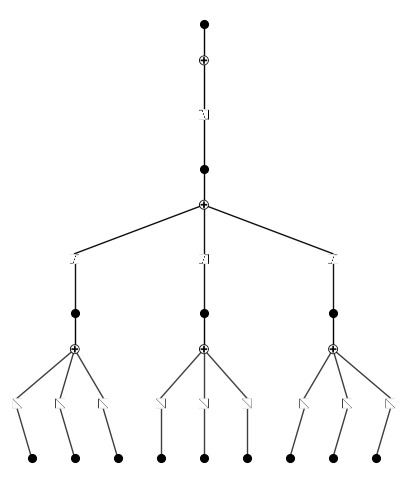

In [6]:
plot(model, train['x']);

**MLP**

In [7]:
import torch
import numpy as np
from xkan import create_dataset_from_data
from xkan.contrib.mlp import MLP

seed = 5
torch.manual_seed(seed)
np.random.seed(seed)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

inputs = []
for i in range(2**9):
    string = "{0:b}".format(i)
    sample = [int(string[i]) for i in range(len(string))]
    sample = (9 - len(sample)) * [0] + sample
    inputs.append(sample)
   
inputs = np.array(inputs).astype(np.float32)
middle = np.array([np.sum(inputs[:,:3], axis=1) > 1.5, np.sum(inputs[:,3:6], axis=1) > 1.5, np.sum(inputs[:,6:9], axis=1) > 1.5]).astype(np.float32)
labels = (np.sum(middle, axis=0) > 1.5).astype(np.float32)[:,None]
inputs = torch.tensor(inputs)
labels = torch.tensor(labels)


train, test = create_dataset_from_data(inputs, labels, device=device)

width = [9, 20, 20, 1]
model = MLP(width=width, seed=seed, device=device)
depth = len(width) - 1

def train_acc():
    return torch.mean(((model(train['x']) > 0.5) == train['y']).float())

def test_acc():
    return torch.mean(((model(test['x']) > 0.5) == test['y']).float())


results = model.fit(train, test, lamb=0.0001, lamb_entropy=2., steps=1000, reg_metric='w', metrics=[train_acc, test_acc], display_metrics=['train_loss', 'train_acc', 'test_acc', 'reg'])
print({k: float(results[k][-1]) for k in ['train_loss', 'train_acc', 'test_acc', 'reg']})

cuda


{'train_loss': 0.009849125519394875, 'train_acc': 1.0, 'test_acc': 1.0, 'reg': 59.54856872558594}


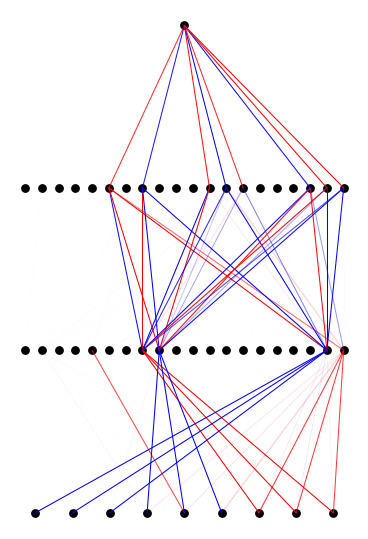

In [8]:
# the MLP baseline (xkan.contrib.mlp.MLP) keeps its own plot and auto_swap methods
model.plot(scale=1.5)

In [9]:
model.auto_swap()

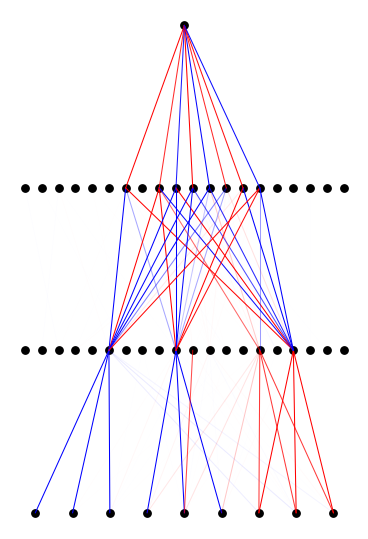

In [10]:
model.plot(scale=1.5)